In [1]:
# import things
"""
Imports all required libraries for building, training, and evaluating the U-Net model.
"""
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import backend as K
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping

2026-01-07 15:57:44.778424: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep (crop/pad/patch/directory structure) must be finalize before attempting this task.
patch_size = 192
patch_dir = "192_Data"

In [3]:
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [4]:
"""
Defines custom segmentation metrics and loss functions.
These help the U-Net learn thin/small roots and handle class imbalance.
"""

def tversky_index(y_true, y_pred, alpha=0.15, beta=0.85, smooth=1e-6):
    """
    Calculates the Tversky index (a Dice-like score).
    alpha controls penalty for false positives, beta controls penalty for false negatives.
    """
    y_true = K.flatten(tf.cast(y_true, tf.float32))
    y_pred = K.flatten(tf.cast(y_pred, tf.float32))
    y_pred = K.clip(y_pred, 1e-6, 1.0 - 1e-6)

    tp = K.sum(y_true * y_pred)
    fp = K.sum((1 - y_true) * y_pred)
    fn = K.sum(y_true * (1 - y_pred))

    return (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)

def focal_tversky_loss(y_true, y_pred, alpha=0.15, beta=0.85, gamma=0.75):
    """
    Turns the Tversky index into a loss.
    gamma makes the loss focus more on hard pixels (misclassified areas).
    """
    ti = tversky_index(y_true, y_pred, alpha=alpha, beta=beta)
    return K.pow((1 - ti), gamma)

def weighted_bce(y_true, y_pred, pos_weight=3.0):
    """
    Computes weighted Binary Cross-Entropy (BCE).
    pos_weight > 1 gives more importance to root pixels to improve recall.
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)

    bce = -(y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    w = 1.0 + (pos_weight - 1.0) * y_true
    return tf.reduce_mean(w * bce)

def bce_focal_tversky_loss(y_true, y_pred):
    """
    Combines weighted BCE and focal Tversky loss into one final loss.
    This balances clean background prediction with better root detection.
    """
    # Fixed weights for reproducibility
    bce_weight = 0.55   
    pos_weight = 3.0    

    bce = weighted_bce(y_true, y_pred, pos_weight=pos_weight)
    ft  = focal_tversky_loss(y_true, y_pred, alpha=0.15, beta=0.85, gamma=0.75)
    return bce_weight * bce + (1.0 - bce_weight) * ft


In [5]:

"""
Builds a small U-Net model for binary root segmentation.
The network uses an encoder (downsampling) + decoder (upsampling) with skip connections
to predict a 1-channel sigmoid mask (root vs background).
"""
def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS):

    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))

    #  Encoder 
    c1 = Conv2D(16, (3,3), activation='relu', padding='same')(inputs)
    c1 = Dropout(0.05)(c1)
    c1 = Conv2D(16, (3,3), activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2,2))(c1)

    c2 = Conv2D(32, (3,3), activation='relu', padding='same')(p1)
    c2 = Dropout(0.05)(c2)
    c2 = Conv2D(32, (3,3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2,2))(c2)

    c3 = Conv2D(64, (3,3), activation='relu', padding='same')(p2)
    c3 = Dropout(0.10)(c3)
    c3 = Conv2D(64, (3,3), activation='relu', padding='same')(c3)
    p3 = MaxPooling2D((2,2))(c3)

    c4 = Conv2D(128, (3,3), activation='relu', padding='same')(p3)
    c4 = Dropout(0.10)(c4)
    c4 = Conv2D(128, (3,3), activation='relu', padding='same')(c4)
    p4 = MaxPooling2D((2,2))(c4)

    # Bottleneck 
    c5 = Conv2D(256, (3,3), activation='relu', padding='same')(p4)
    c5 = Dropout(0.20)(c5)
    c5 = Conv2D(256, (3,3), activation='relu', padding='same')(c5)

    #  Decoder 
    u6 = Conv2DTranspose(128, (2,2), strides=(2,2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(128, (3,3), activation='relu', padding='same')(u6)
    c6 = Dropout(0.10)(c6)
    c6 = Conv2D(128, (3,3), activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(64, (2,2), strides=(2,2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(64, (3,3), activation='relu', padding='same')(u7)
    c7 = Dropout(0.10)(c7)
    c7 = Conv2D(64, (3,3), activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(32, (2,2), strides=(2,2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(32, (3,3), activation='relu', padding='same')(u8)
    c8 = Dropout(0.05)(c8)
    c8 = Conv2D(32, (3,3), activation='relu', padding='same')(c8)

    u9 = Conv2DTranspose(16, (2,2), strides=(2,2), padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(16, (3,3), activation='relu', padding='same')(u9)
    c9 = Dropout(0.05)(c9)
    c9 = Conv2D(16, (3,3), activation='relu', padding='same')(c9)

    outputs = Conv2D(1, (1,1), activation='sigmoid')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

In [6]:
# Build U-Net
# REQUIREMENT: Model summary must be visible
model = simple_unet_model(192, 192, 1)
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss= bce_focal_tversky_loss,
    metrics=[f1]
)
model.summary()

2026-01-07 15:58:33.707602: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1767801513.714261 3971873 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 42109 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 192, 192,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 192, 192,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 192, 192,  │          0 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 192, 192,  │      2,320 │ dropout[0][0]     │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 96, 96,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 96, 96,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 96, 96,    │          0 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 96, 96,    │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 48, 48,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 48, 48,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 48, 48,    │          0 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 48, 48,    │     36,928 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 24, 24,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 24, 24,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 24, 24,    │          0 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 24, 24,    │    147,584 │ dropout_3[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 12, 12,    │          0 │ conv2d_7[0][0]  

 Total params: 1,940,817 (7.40 MB)

 Trainable params: 1,940,817 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Setup a generator for training
"""
Creates image generators that load training image patches and mask patches from folders.
The generators also rescale pixel values to [0, 1] so the model trains more stably.
"""
datagen = ImageDataGenerator(rescale=1./255)
# Loads training input images (grayscale) in batches
train_img_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "train_images"),
    target_size=(patch_size, patch_size),  
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=1
)
# Loads training masks (grayscale) in batches (same seed so images and masks stay aligned)
train_mask_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "train_masks"),
    target_size=(patch_size, patch_size),  
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=1
)

Found 399475 images belonging to 1 classes.
Found 399475 images belonging to 1 classes.


In [8]:
"""
Creates validation generators that load validation image patches and mask patches.
These are used only for evaluation during training (not for updating model weights).
"""
# Setup validation generator (uses a different seed than training)
val_img_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "val_images"),
    target_size=(patch_size, patch_size),
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=2,
)

# Validation masks (same seed as val_img_gen so images and masks match)
val_mask_gen = datagen.flow_from_directory(
    os.path.join(patch_dir, "val_masks"),
    target_size=(patch_size, patch_size),
    class_mode=None,
    color_mode="grayscale",
    batch_size=16,
    seed=2,
)


Found 14297 images belonging to 1 classes.
Found 14297 images belonging to 1 classes.


In [9]:
"""
Creates training callbacks to improve training stability.
EarlyStopping stops training when validation loss stops improving, and restores the best model.
ReduceLROnPlateau lowers the learning rate when validation loss plateaus to help generalization.
"""

# Stops training if val_loss does not improve, and keeps the best weights
cb = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Reduces the learning rate when val_loss stops improving
from keras.callbacks import ReduceLROnPlateau

rlr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


In [10]:
"""
Combines the image generator and mask generator so the model receives (image, mask) pairs.
Then trains the model with visible epoch logs, including validation loss and validation F1.
"""
# This is where the magic happens
# REQUIREMENT: The epoch logs must be visible showing validation loss and validation f1.
def combined_generator(img_gen, mask_gen):
    # Both have the same number of batches per epoch
    num_batches = len(img_gen)
    while True:
        for i in range(num_batches):
            yield img_gen[i], mask_gen[i]

# Training and validation generators that output (X, y)
train_generator = combined_generator(train_img_gen, train_mask_gen)
val_generator   = combined_generator(val_img_gen,  val_mask_gen)

# Train the model and record training history (loss + metrics per epoch)
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_img_gen),
    validation_data=val_generator,
    validation_steps=len(val_img_gen),
    epochs=50,
    callbacks=[cb, rlr]
)


Epoch 1/50


2026-01-07 16:01:42.300627: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fe568027b20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-07 16:01:42.300654: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX A6000, Compute Capability 8.6
2026-01-07 16:01:42.412069: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-07 16:01:44.422242: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90701


    6/24968 ━━━━━━━━━━━━━━━━━━━━ 9:27 23ms/step - f1: 0.0062 - loss: 0.8263    

I0000 00:00:1767801717.552177 3973165 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


24968/24968 ━━━━━━━━━━━━━━━━━━━━ 569s 22ms/step - f1: 0.6002 - loss: 0.1868 - val_f1: 0.7201 - val_loss: 0.1113 - learning_rate: 1.0000e-04
Epoch 2/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 529s 21ms/step - f1: 0.6830 - loss: 0.1430 - val_f1: 0.7374 - val_loss: 0.1049 - learning_rate: 1.0000e-04
Epoch 3/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 527s 21ms/step - f1: 0.6989 - loss: 0.1351 - val_f1: 0.7529 - val_loss: 0.1002 - learning_rate: 1.0000e-04
Epoch 4/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 528s 21ms/step - f1: 0.7073 - loss: 0.1308 - val_f1: 0.7542 - val_loss: 0.0991 - learning_rate: 1.0000e-04
Epoch 5/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 531s 21ms/step - f1: 0.7137 - loss: 0.1275 - val_f1: 0.7605 - val_loss: 0.0980 - learning_rate: 1.0000e-04
Epoch 6/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 529s 21ms/step - f1: 0.7172 - loss: 0.1256 - val_f1: 0.7740 - val_loss: 0.0949 - learning_rate: 1.0000e-04
Epoch 7/50
24968/24968 ━━━━━━━━━━━━━━━━━━━━ 528s 21ms/step - f1: 0.7203 - loss: 0.1241 - val_f1: 0.7695 -

In [11]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.h5'
example_file_name = f'ahmed_245226_unet_model_{patch_size}px.h5'
print(example_file_name)
model.save(example_file_name)

ahmed_245226_unet_model_192px.h5


In [12]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.09103690832853317
Best validation f1: 0.799167275428772


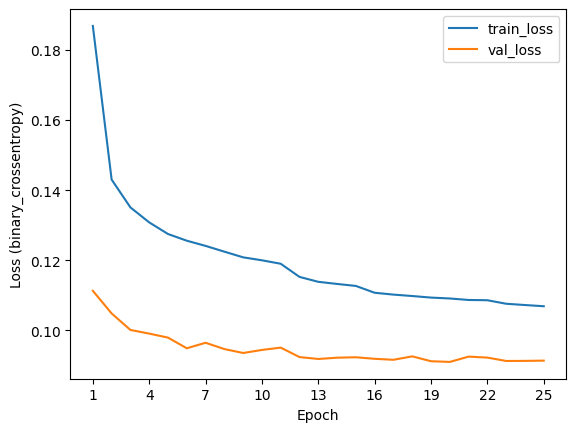

In [13]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

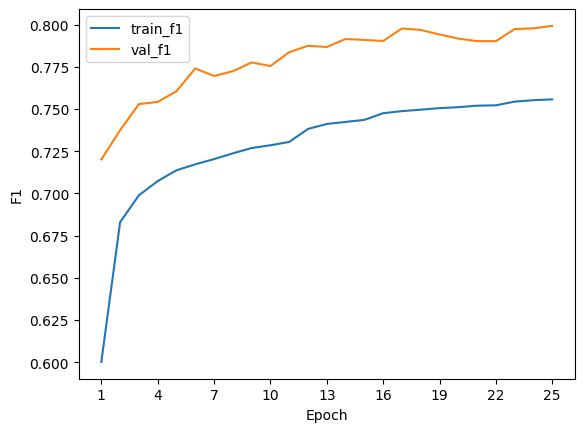

In [14]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))